# Tarea 11 — Predicción de defectos de software
## Comparación entre Gaussian Naive Bayes y Regresión Logística (KC1)

> Uriel Aguilar Mauricio

# 1. Introducción

La **predicción de defectos de software** consiste en estimar, a partir de métricas extraídas de módulos de código, cuáles presentan mayor riesgo de contener defectos. Esta predicción no comprueba por sí sola si un módulo contiene un error; su utilidad es **orientar el esfuerzo de pruebas, revisión e inspección** hacia los módulos potencialmente más problemáticos.

En esta práctica se comparan dos enfoques de clasificación binaria:

- **Gaussian Naive Bayes (GNB):** aplica la regla de Bayes y supone que las características son condicionalmente independientes dada la clase; además, modela cada característica continua mediante una distribución normal para cada clase.
- **Regresión Logística (RL):** estima la probabilidad de la clase positiva mediante una función logística aplicada a una combinación lineal de las características. Se escalan las variables antes de entrenarla.

La clase de interés es la minoritaria: **`defects = 1`**, porque una predicción negativa incorrecta (*falso negativo*) podría dejar un módulo defectuoso sin inspección prioritaria. Por tanto, además de la exactitud global (*Accuracy*), son fundamentales *Recall* y *F1-score* de la clase positiva.


# 2. Metodología

## 2.1. Entorno y bibliotecas

In [2]:
import sys

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from scipy.io import arff
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score
)

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 115)
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'axes.grid': False})

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| Pandas:', pd.__version__, '| SciPy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__, '| Matplotlib:', matplotlib.__version__)

Python: 3.13.1
NumPy: 2.5.2 | Pandas: 3.0.5 | SciPy: 1.18.1
scikit-learn: 1.9.0 | Matplotlib: 3.11.1


## 2.2. Carga de KC1

In [3]:
data, meta = arff.loadarff("../data/raw/kc1.arff")

df = pd.DataFrame(data)

In [4]:
df.head(5)

,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,b,t,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,1.30,1.30,2.0,2.0,2.0,2.0,1.2,1.2,1.2,1.2,1.4,b'false'
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,b'true'
2,83.0,11.0,1.0,11.0,171.0,927.89,0.04,23.04,40.27,21378.61,0.31,1187.70,65.0,10.0,6.0,0.0,18.0,25.0,107.0,64.0,21.0,b'true'
3,46.0,8.0,6.0,8.0,141.0,769.78,0.07,14.86,51.81,11436.73,0.26,635.37,37.0,2.0,5.0,0.0,16.0,28.0,89.0,52.0,15.0,b'true'
4,25.0,3.0,1.0,3.0,58.0,254.75,0.11,9.35,27.25,2381.95,0.08,132.33,21.0,0.0,2.0,0.0,11.0,10.0,41.0,17.0,5.0,b'true'


In [6]:
valores_etiqueta = df['defects'].map(
    lambda v: v.decode('utf-8').strip().lower() if isinstance(v, bytes)
    else str(v).strip().lower()
)

df['defects'] = valores_etiqueta.map({'false': 0, 'true': 1}).astype(int)
X = df.drop(columns=['defects']).copy()
y = df['defects'].copy()


## 2.3. Exploración y control de calidad de datos

Se comprueba la existencia de valores faltantes o infinitos, se cuantifica el desbalance y se identifican registros duplicados. **No se eliminan duplicados** porque la consigna exige comparar los clasificadores utilizando KC1 y no solicita depuración del conjunto. La presencia de duplicados se discute posteriormente como una **amenaza a la validez** de las métricas.

In [8]:
conteo = y.value_counts().reindex([0, 1], fill_value=0)
resumen = pd.DataFrame({
    'Clase': ['No defectuoso (0)', 'Defectuoso (1)'],
    'Cantidad': [int(conteo.loc[0]), int(conteo.loc[1])],
    'Porcentaje (%)': [(conteo.loc[0]/len(y))*100, (conteo.loc[1]/len(y))*100]
})

nulos = int(df.isna().sum().sum())
infinitos = int(np.isinf(X.to_numpy(dtype=float)).sum())
dup_exactos = int(df.duplicated().sum())
dup_predictores = int(X.duplicated().sum())
etiquetas_contradictorias = int(df.groupby(list(X.columns), dropna=False)['defects'].nunique().gt(1).sum())

print(f'Faltantes: {nulos} | Infinitos: {infinitos}')
print(f'Filas totalmente duplicadas: {dup_exactos}')
print(f'Filas con predictores duplicados: {dup_predictores}')
print(f'Patrones de predictores asociados con ambas clases: {etiquetas_contradictorias}')
display(resumen.style.format({'Porcentaje (%)':'{:.2f}'}).hide(axis='index'))


Faltantes: 0 | Infinitos: 0
Filas totalmente duplicadas: 897
Filas con predictores duplicados: 917
Patrones de predictores asociados con ambas clases: 20


Clase,Cantidad,Porcentaje (%)
No defectuoso (0),1783,84.54
Defectuoso (1),326,15.46


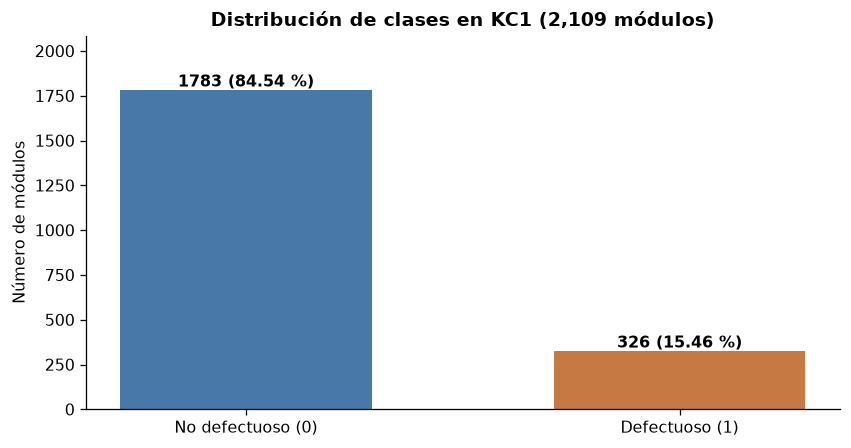

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
colores = ['#4878A8', '#C67943']
barras = ax.bar(resumen['Clase'], resumen['Cantidad'], color=colores, width=.58)
for barra, pct in zip(barras, resumen['Porcentaje (%)']):
    ax.text(barra.get_x()+barra.get_width()/2, barra.get_height()+19,
            f'{int(barra.get_height())} ({pct:.2f} %)', ha='center', fontsize=10, weight='bold')
ax.set_ylim(0, max(conteo)*1.17)
ax.set_title('Distribución de clases en KC1 (2,109 módulos)', weight='bold')
ax.set_ylabel('Número de módulos')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

### Dependencia entre métricas del código

La independencia condicional exigida por Naive Bayes no se puede demostrar mediante una correlación simple (la correlación marginal y la condicional no son equivalentes). Sin embargo, correlaciones casi perfectas entre métricas constituyen **indicios descriptivos** de dependencia que hacen cuestionable esa suposición en este problema.

Pares de características altamente relacionadas (correlación de Pearson absoluta):


Métrica A,Métrica B,Correlación |r|
e,t,1.000000
v(g),branchCount,0.998608
n,total_Op,0.998146
n,total_Opnd,0.995162
n,v,0.994956
v,total_Op,0.992046
v,total_Opnd,0.991866
total_Op,total_Opnd,0.987338


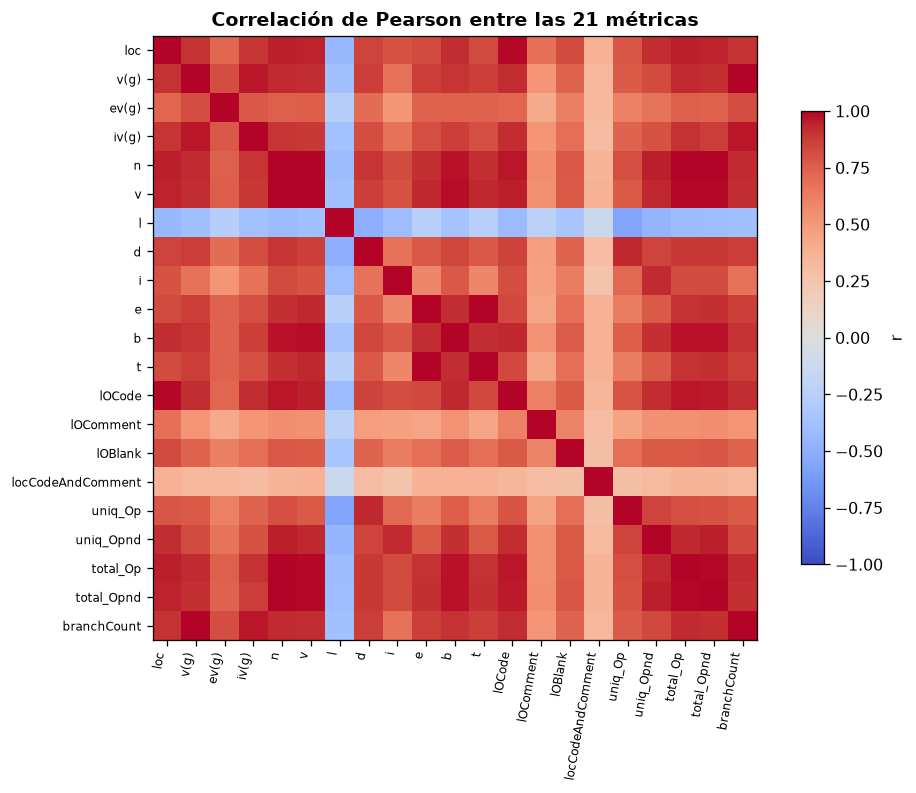

In [10]:
corr_abs = X.corr(numeric_only=True).abs()
triangulo_superior = np.triu(np.ones(corr_abs.shape, dtype=bool), k=1)
pares = (corr_abs.where(triangulo_superior).stack()
         .sort_values(ascending=False).head(8)
         .rename('Correlación |r|').reset_index())
pares.columns = ['Métrica A', 'Métrica B', 'Correlación |r|']
print('Pares de características altamente relacionadas (correlación de Pearson absoluta):')
display(pares.style.format({'Correlación |r|':'{:.6f}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(X.corr(numeric_only=True), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(X.shape[1]), X.columns, rotation=80, ha='right', fontsize=7.7)
ax.set_yticks(range(X.shape[1]), X.columns, fontsize=7.7)
ax.set_title('Correlación de Pearson entre las 21 métricas', weight='bold')
fig.colorbar(im, ax=ax, label='r', shrink=.75)
plt.tight_layout()
plt.show()

<## 2.4. División 70 % entrenamiento / 30 % prueba

Se aplica literalmente `train_test_split()` con los dos parámetros obligatorios. Se añade `stratify=y` para mantener la distribución de las dos clases, importante ante el desbalance de KC1. **Ambos clasificadores usan exactamente el mismo subconjunto de prueba**.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
assert len(X_train) == 1476 and len(X_test) == 633
assert X_train.index.intersection(X_test.index).empty

filas_particion = pd.DataFrame({
    'Partición':['Entrenamiento','Prueba'],
    'Total módulos':[len(X_train),len(X_test)],
    'No defectuosos (0)':[(y_train==0).sum(),(y_test==0).sum()],
    'Defectuosos (1)':[(y_train==1).sum(),(y_test==1).sum()],
    'Prevalencia defectos (%)':[y_train.mean()*100, y_test.mean()*100]
})
display(filas_particion.style.format({'Prevalencia defectos (%)':'{:.2f}'}).hide(axis='index'))

Partición,Total módulos,No defectuosos (0),Defectuosos (1),Prevalencia defectos (%)
Entrenamiento,1476,1248,228,15.45
Prueba,633,535,98,15.48


## 2.5. Clasificador A — Gaussian Naive Bayes

El modelo asigna una clase según la regla de Bayes:

$$P(y\mid x) \propto P(y)\prod_{j=1}^{p}P(x_j\mid y),\qquad x_j\mid y\sim\mathcal{N}(\mu_{jy},\sigma_{jy}^{2}).$$

Se utiliza `GaussianNB()` con parámetros predeterminados. Los datos de prueba **no** se usan en `fit()`.

In [12]:
modelo_nb = GaussianNB()
modelo_nb.fit(X_train, y_train)

pred_nb = modelo_nb.predict(X_test)
prob_nb = modelo_nb.predict_proba(X_test)[:, list(modelo_nb.classes_).index(1)]
assert len(pred_nb) == len(prob_nb) == len(X_test)
assert np.all((prob_nb >= 0) & (prob_nb <= 1))

print('GaussianNB entrenado.')
print('Clases:', modelo_nb.classes_, '| Predichos como defectuosos:', int(pred_nb.sum()))
print('Ejemplo de 5 predicciones y probabilidades de defectos:')
display(pd.DataFrame({'Real':y_test.to_numpy()[:5],
                      'Predicción NB':pred_nb[:5],
                      'P(defects=1) NB':prob_nb[:5]}).style.format({'P(defects=1) NB':'{:.4f}'}))

GaussianNB entrenado.
Clases: [0 1] | Predichos como defectuosos: 73
Ejemplo de 5 predicciones y probabilidades de defectos:


,Real,Predicción NB,P(defects=1) NB
0,0,0,0.0000
1,0,0,0.0000
2,0,0,0.0000
3,0,0,0.3134
4,0,0,0.0000


## 2.6. Clasificador B — Regresión Logística con estandarización

Para un vector de características previamente estandarizadas, la Regresión Logística aproxima:

$$P(y=1\mid x)=\sigma\!\left(\beta_0+\sum_{j=1}^{p}\beta_j z_j\right),\quad
\sigma(t)=\frac{1}{1+e^{-t}},\quad z_j=\frac{x_j-\mu_{j,\mathrm{train}}}{s_{j,\mathrm{train}}}.$$

`StandardScaler()` calcula las medias y desviaciones **solamente con el conjunto de entrenamiento**. El `Pipeline` garantiza que esta transformación se aplique después a la prueba sin volver a ajustarla. `max_iter=5000` reduce el riesgo de finalizar por el límite de iteraciones.

In [13]:
modelo_rl = Pipeline(steps=[
    ('escalador', StandardScaler()),
    ('clasificador', LogisticRegression(max_iter=5000, random_state=42))
])
modelo_rl.fit(X_train, y_train)

pred_rl = modelo_rl.predict(X_test)
prob_rl = modelo_rl.predict_proba(X_test)[:, list(modelo_rl.classes_).index(1)]
assert len(pred_rl) == len(prob_rl) == len(X_test)
assert np.all((prob_rl >= 0) & (prob_rl <= 1))

print('Regresión Logística entrenada con StandardScaler mediante Pipeline.')
print('Clases:', modelo_rl.classes_, '| Predichos como defectuosos:', int(pred_rl.sum()))
print('Iteraciones consumidas:', modelo_rl.named_steps['clasificador'].n_iter_[0])
print('Ejemplo de 5 predicciones y probabilidades de defectos:')
display(pd.DataFrame({'Real':y_test.to_numpy()[:5],
                      'Predicción RL':pred_rl[:5],
                      'P(defects=1) RL':prob_rl[:5]}).style.format({'P(defects=1) RL':'{:.4f}'}))

Regresión Logística entrenada con StandardScaler mediante Pipeline.
Clases: [0 1] | Predichos como defectuosos: 25
Iteraciones consumidas: 41
Ejemplo de 5 predicciones y probabilidades de defectos:


,Real,Predicción RL,P(defects=1) RL
0,0,0,0.0216
1,0,0,0.1094
2,0,0,0.0747
3,0,0,0.2714
4,0,0,0.1876


# 3. Resultados y evidencias de ejecución
## 3.1. Métricas 

En todas las fórmulas, **la clase positiva es `defects = 1`**:

- **TP:** defectuosos correctamente detectados; **TN:** no defectuosos correctamente reconocidos.
- **FP:** no defectuosos clasificados como defectuosos; **FN:** defectuosos que no fueron detectados.

$$\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$
$$\mathrm{Precision}=\frac{TP}{TP+FP}$$
$$\mathrm{Recall}=\frac{TP}{TP+FN}$$
$$\mathrm{F1}=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}$$

Se utilizan las funciones de `sklearn.metrics`: `accuracy_score`, `precision_score`, `recall_score`, `f1_score`. `zero_division=0` solo define el comportamiento ante una división sin predicciones positivas.

In [16]:
def calcular_metricas(y_real, y_predicho):
    return {
        'Accuracy': accuracy_score(y_real, y_predicho),
        'Precision': precision_score(y_real, y_predicho, pos_label=1, zero_division=0),
        'Recall': recall_score(y_real, y_predicho, pos_label=1, zero_division=0),
        'F1 Score': f1_score(y_real, y_predicho, pos_label=1, zero_division=0)
    }

metricas_nb = calcular_metricas(y_test, pred_nb)
metricas_rl = calcular_metricas(y_test, pred_rl)
comparacion = pd.DataFrame({
    'Gaussian NB': metricas_nb,
    'Logistic Regression': metricas_rl
}).reindex(['Accuracy','Precision','Recall','F1 Score'])

print('Tabla principal de comparación — valores en escala 0 a 1:')
display(comparacion.style.format('{:.4f}').set_caption('Evaluación sobre los mismos 633 módulos de prueba'))
print('\nTabla de porcentajes:')
display((comparacion*100).style.format('{:.2f} %'))

for nombre, pred, met in [
    ('Gaussian NB', pred_nb, metricas_nb),
    ('Logistic Regression', pred_rl, metricas_rl)
]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    f1_manual = 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn)>0 else 0
    assert np.isclose(f1_manual, met['F1 Score']), f'Error de consistencia en {nombre}'

Tabla principal de comparación — valores en escala 0 a 1:


,Gaussian NB,Logistic Regression
Accuracy,0.8310,0.8531
Precision,0.4384,0.6000
Recall,0.3265,0.1531
F1 Score,0.3743,0.2439



Tabla de porcentajes:


,Gaussian NB,Logistic Regression
Accuracy,83.10 %,85.31 %
Precision,43.84 %,60.00 %
Recall,32.65 %,15.31 %
F1 Score,37.43 %,24.39 %


## 3.2. Matrices de confusión y reportes de clasificación

En cada matriz, las **filas** representan clases reales y las **columnas** clases predichas. La celda superior derecha es **FP** y la inferior izquierda es **FN**; ambas son importantes para aseguramiento de calidad.

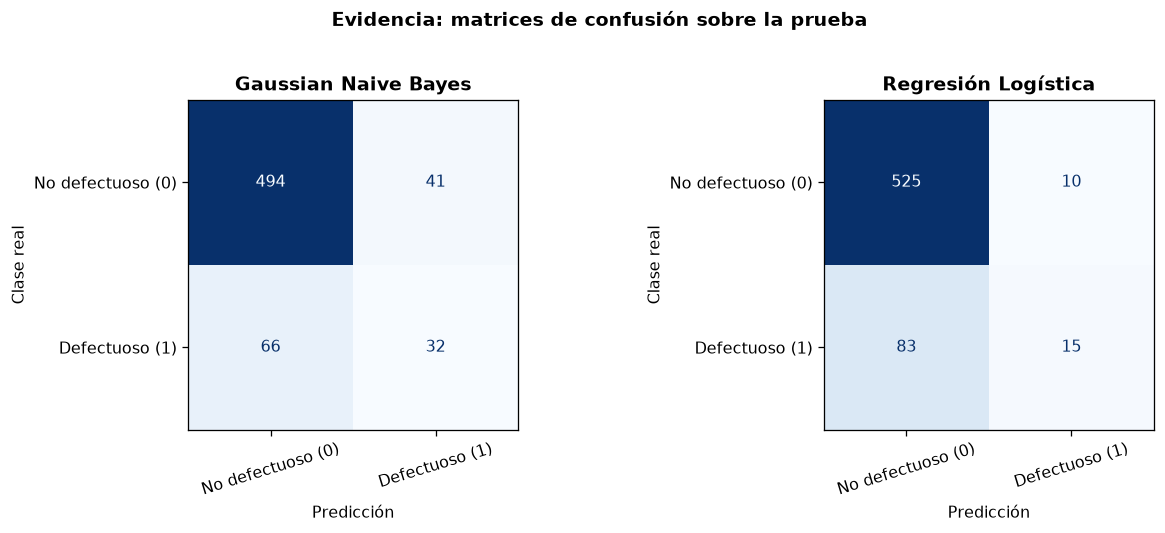

In [18]:
cm_nb = confusion_matrix(y_test, pred_nb, labels=[0,1])
cm_rl = confusion_matrix(y_test, pred_rl, labels=[0,1])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
for ax, cm, titulo in zip(axes, [cm_nb, cm_rl], ['Gaussian Naive Bayes', 'Regresión Logística']):
    plot_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No defectuoso (0)','Defectuoso (1)']
    )
    plot_cm.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=17)
    ax.set_title(titulo, fontsize=12, weight='bold')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Clase real')
plt.suptitle('Evidencia: matrices de confusión sobre la prueba', y=1.02, weight='bold')
plt.tight_layout()
plt.show()

In [20]:
for nombre, cm, pred in [
    ('Gaussian NB', cm_nb, pred_nb),
    ('Regresión Logística', cm_rl, pred_rl)
]:
    tn, fp, fn, tp = cm.ravel()
    print(f'\n{nombre}: TP={tp}, TN={tn}, FP={fp}, FN={fn}')
    print(classification_report(y_test, pred,
          labels=[0,1], target_names=['No defectuoso (0)','Defectuoso (1)'],
          digits=4, zero_division=0))


Gaussian NB: TP=32, TN=494, FP=41, FN=66
                   precision    recall  f1-score   support

No defectuoso (0)     0.8821    0.9234    0.9023       535
   Defectuoso (1)     0.4384    0.3265    0.3743        98

         accuracy                         0.8310       633
        macro avg     0.6602    0.6249    0.6383       633
     weighted avg     0.8134    0.8310    0.8205       633


Regresión Logística: TP=15, TN=525, FP=10, FN=83
                   precision    recall  f1-score   support

No defectuoso (0)     0.8635    0.9813    0.9186       535
   Defectuoso (1)     0.6000    0.1531    0.2439        98

         accuracy                         0.8531       633
        macro avg     0.7317    0.5672    0.5813       633
     weighted avg     0.8227    0.8531    0.8142       633



## 3.3. Comparación visual de las cuatro métricas

Esta gráfica y la tabla anterior ofrecen **evidencia visual de ejecución** dentro de la propia libreta, sin depender de imágenes externas. Las cuatro barras de cada serie corresponden directamente a las métricas calculadas por Scikit-Learn.

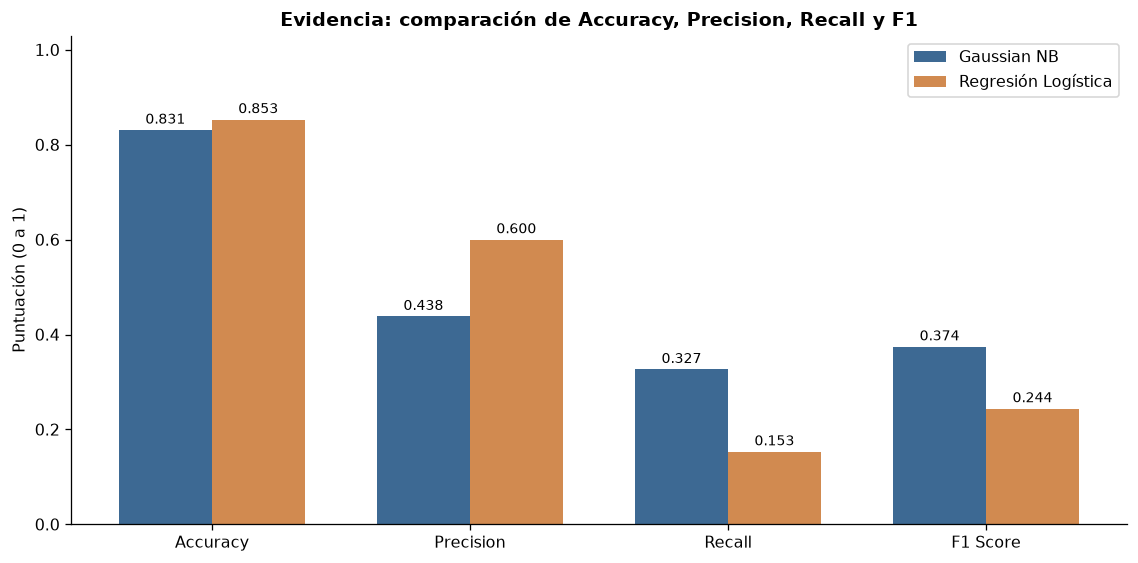

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
pos = np.arange(len(comparacion))
w=.36
bars_nb=ax.bar(pos-w/2, comparacion['Gaussian NB'], w, label='Gaussian NB', color='#3D6993')
bars_rl=ax.bar(pos+w/2, comparacion['Logistic Regression'], w, label='Regresión Logística', color='#D18A50')
for bars in [bars_nb,bars_rl]:
    for b in bars:
        ax.annotate(f'{b.get_height():.3f}', (b.get_x()+b.get_width()/2,b.get_height()),
                    xytext=(0,4), textcoords='offset points', ha='center',fontsize=9)
ax.set_xticks(pos, comparacion.index)
ax.set_ylim(0,1.03)
ax.set_ylabel('Puntuación (0 a 1)')
ax.set_title('Evidencia: comparación de Accuracy, Precision, Recall y F1', weight='bold')
ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

## 3.4. Probabilidades y curvas complementarias (ROC y Precision–Recall)

A diferencia de `predict()`, `predict_proba()` conserva un valor de probabilidad para la clase 1. La **ROC-AUC** resume capacidad de ordenar positivos antes que negativos, mientras que **Average Precision (AP)** resume el comportamiento de precisión frente a exhaustividad en diferentes umbrales. Son **indicadores complementarios**: no sustituyen ninguna de las cuatro métricas solicitadas ni implican que las probabilidades estén calibradas.

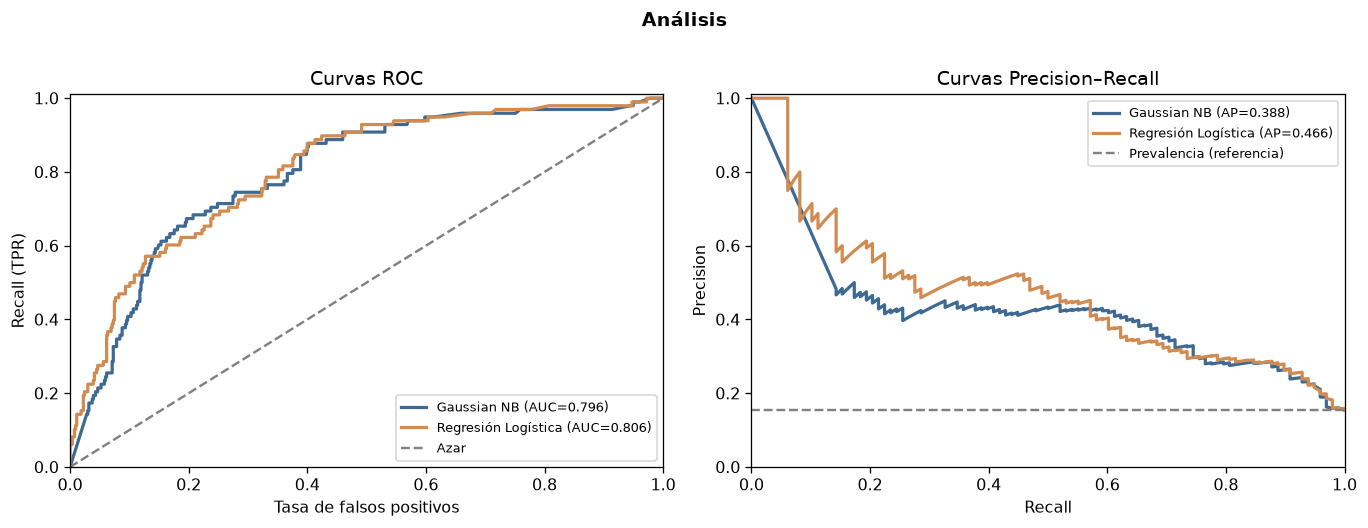

,ROC-AUC,Average Precision (AP)
Gaussian NB,0.7964,0.3877
Regresión Logística,0.8058,0.4663


In [24]:
roc_nb = roc_auc_score(y_test, prob_nb)
roc_rl = roc_auc_score(y_test, prob_rl)
ap_nb = average_precision_score(y_test, prob_nb)
ap_rl = average_precision_score(y_test, prob_rl)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, probs, color in [('Gaussian NB',prob_nb,'#3D6993'),('Regresión Logística',prob_rl,'#D18A50')]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    precision, recall, _ = precision_recall_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=f'{nombre} (AUC={roc_auc_score(y_test,probs):.3f})', color=color, lw=2)
    axes[1].plot(recall, precision, label=f'{nombre} (AP={average_precision_score(y_test,probs):.3f})', color=color, lw=2)
axes[0].plot([0,1],[0,1],'--',color='gray',label='Azar')
axes[0].set(title='Curvas ROC',xlabel='Tasa de falsos positivos',ylabel='Recall (TPR)',xlim=(0,1),ylim=(0,1.01))
axes[1].axhline(y_test.mean(),linestyle='--',color='gray',label='Prevalencia (referencia)')
axes[1].set(title='Curvas Precision–Recall',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.01))
for ax in axes: ax.legend(loc='best',fontsize=8)
fig.suptitle('Análisis',weight='bold',y=1.01)
plt.tight_layout()
plt.show()

display(pd.DataFrame({'ROC-AUC':[roc_nb,roc_rl], 'Average Precision (AP)':[ap_nb,ap_rl]},
                     index=['Gaussian NB','Regresión Logística']).style.format('{:.4f}'))

## 3.5. Interpretación de coeficientes de Regresión Logística

La regresión permite observar el sentido de cada coeficiente **condicionando por las demás variables**: para una variación de una desviación estándar en una métrica, su coeficiente representa un cambio en los *log-odds*, manteniendo las demás constantes. La razón de posibilidades (*odds ratio*) es $e^{\beta_j}$. **No significa causalidad**; además, la colinealidad entre métricas de KC1 puede volver inestables los coeficientes individuales.

In [26]:
coef = modelo_rl.named_steps['clasificador'].coef_[0]
coeficientes = pd.DataFrame({
    'Métrica':X.columns,
    'Coeficiente (por 1 desviación estándar)':coef,
    'Odds ratio':np.exp(np.clip(coef,-700,700))
}).sort_values('Coeficiente (por 1 desviación estándar)', ascending=False)
print('Variables con mayor coeficiente positivo y mayor coeficiente negativo:')
display(pd.concat([coeficientes.head(5), coeficientes.tail(5)],ignore_index=True)
        .style.format({'Coeficiente (por 1 desviación estándar)':'{:.4f}','Odds ratio':'{:.4f}'}))

seleccion = coeficientes.iloc[np.argsort(-np.abs(coeficientes['Coeficiente (por 1 desviación estándar)'].to_numpy()))[:10]]
seleccion = seleccion.sort_values('Coeficiente (por 1 desviación estándar)')


Variables con mayor coeficiente positivo y mayor coeficiente negativo:


,Métrica,Coeficiente (por 1 desviación estándar),Odds ratio
0,d,0.8032,2.2327
1,iv(g),0.7099,2.0337
2,b,0.6621,1.9389
3,loc,0.6375,1.8918
4,i,0.5990,1.8204
5,v,-0.3747,0.6875
6,lOCode,-0.3835,0.6814
7,n,-0.5618,0.5702
8,total_Op,-1.1222,0.3256
9,v(g),-1.1780,0.3079


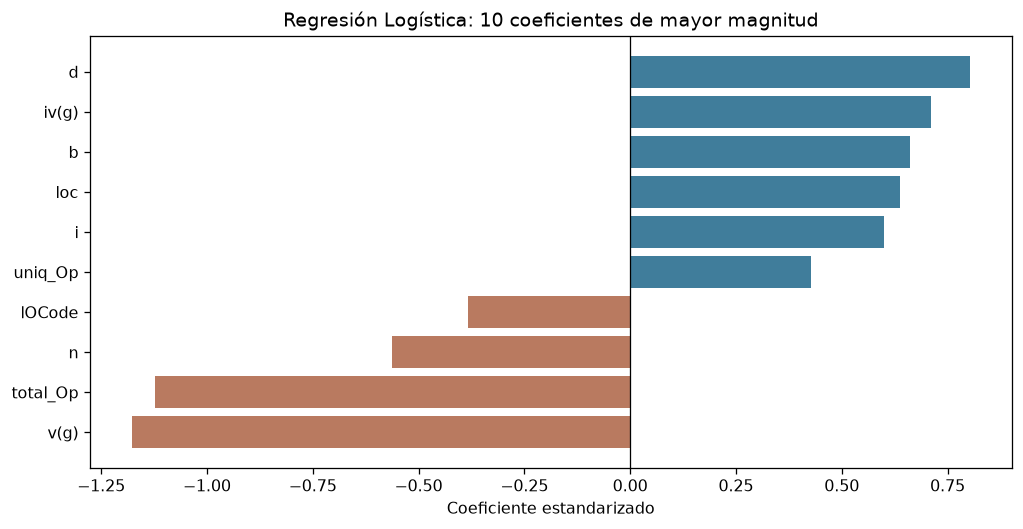

In [27]:
fig, ax=plt.subplots(figsize=(9,4.7))
ax.barh(seleccion['Métrica'],seleccion['Coeficiente (por 1 desviación estándar)'],
        color=['#407D9B' if v>=0 else '#B97A60' for v in seleccion['Coeficiente (por 1 desviación estándar)']])
ax.axvline(0,color='black',linewidth=.8)
ax.set(xlabel='Coeficiente estandarizado',title='Regresión Logística: 10 coeficientes de mayor magnitud')
plt.tight_layout()
plt.show()

## 3.6. Comparación con un clasificador 

Para interpretar correctamente `Accuracy` en un conjunto desbalanceado, se calcula una **línea base adicional** que predice siempre la clase mayoritaria (0). Esta línea base **no es un tercer modelo solicitado**; solo ayuda a juzgar si acertar muchas observaciones implica detectar defectos.

In [28]:
base = DummyClassifier(strategy='most_frequent')
base.fit(X_train,y_train)
acierto_base=accuracy_score(y_test,base.predict(X_test))
print(f'Accuracy de la línea base (siempre 0): {acierto_base:.4f} ({acierto_base*100:.2f} %)')
print(f'Accuracy de Gaussian NB:                  {metricas_nb["Accuracy"]:.4f} ({metricas_nb["Accuracy"]*100:.2f} %)')
print(f'Accuracy de Regresión Logística:          {metricas_rl["Accuracy"]:.4f} ({metricas_rl["Accuracy"]*100:.2f} %)')
print('Recall y F1 de la línea base para defectos: 0; no detecta ningún módulo defectuoso.')

Accuracy de la línea base (siempre 0): 0.8452 (84.52 %)
Accuracy de Gaussian NB:                  0.8310 (83.10 %)
Accuracy de Regresión Logística:          0.8531 (85.31 %)
Recall y F1 de la línea base para defectos: 0; no detecta ningún módulo defectuoso.


## 3.7. Validar
La separación por filas mantiene índices distintos, pero **no impide que el mismo vector de 21 métricas exista tanto en entrenamiento como en prueba**. Se cuantifica ese solapamiento sin modificar los resultados obligatorios. Los registros del mismo proyecto y la alta duplicación impiden asumir independencia de ejemplos o generalización automática a otros proyectos.

In [29]:
indices_train = pd.MultiIndex.from_frame(X_train)
indices_test = pd.MultiIndex.from_frame(X_test)
coincidencias_test = indices_test.isin(indices_train)
print(f'Registros en prueba con mismas 21 métricas presentes en entrenamiento: '
      f'{coincidencias_test.sum()} de {len(X_test)} ({coincidencias_test.mean()*100:.2f} %)')
print('Observación: no se supone que todos sean el mismo módulo, solo que sus métricas coinciden.')

Registros en prueba con mismas 21 métricas presentes en entrenamiento: 339 de 633 (53.55 %)
Observación: no se supone que todos sean el mismo módulo, solo que sus métricas coinciden.


### Verificación por modelo

Como contraste de sensibilidad, se ejecuta **una segunda partición exploratoria**, agrupando filas que poseen vectores idénticos de métricas, para evitar solapamiento de `X` entre entrenamiento y prueba. Esta comprobación **no reemplaza** el protocolo `train_test_split(0.30, 42)` requerido y **no es directamente comparable** con la tabla principal: cambia la composición de clases y el tamaño del conjunto de prueba. Su objetivo es transparentar la limitación detectada.

In [31]:
grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
separador = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
idx_train_g, idx_test_g = next(separador.split(X, y, groups=grupos))
assert not set(grupos[idx_train_g]).intersection(set(grupos[idx_test_g]))
X_train_g, X_test_g = X.iloc[idx_train_g], X.iloc[idx_test_g]
y_train_g, y_test_g = y.iloc[idx_train_g], y.iloc[idx_test_g]

nb_g = GaussianNB().fit(X_train_g,y_train_g)
rl_g = Pipeline([('escalador',StandardScaler()),
                 ('clasificador',LogisticRegression(max_iter=5000,random_state=42))])
rl_g.fit(X_train_g,y_train_g)
metricas_grupos = pd.DataFrame({
    'Gaussian NB':calcular_metricas(y_test_g,nb_g.predict(X_test_g)),
    'Logistic Regression':calcular_metricas(y_test_g,rl_g.predict(X_test_g))
})
print(f'Partición agrupada: entrenamiento={len(idx_train_g)}, prueba={len(idx_test_g)}; '
      f'prevalencia prueba={y_test_g.mean()*100:.2f} %')
print('Resultados de sensibilidad (NO son los de entrega principal):')
display(metricas_grupos.style.format('{:.4f}'))

Partición agrupada: entrenamiento=1332, prueba=777; prevalencia prueba=13.38 %
Resultados de sensibilidad (NO son los de entrega principal):


,Gaussian NB,Logistic Regression
Accuracy,0.8559,0.8790
Precision,0.4545,0.6562
Recall,0.3846,0.2019
F1 Score,0.4167,0.3088


# 4. Discusión crítica de los resultados

### 1. ¿Qué modelo obtuvo el mejor desempeño general?

La **Regresión Logística** presenta mayor *Accuracy* (**85.31 % frente a 83.10 %**) y *Precision* (**60.00 % frente a 43.84 %**). Sin embargo, **Gaussian Naive Bayes** obtiene mejor *Recall* (**32.65 % frente a 15.31 %**) y mejor *F1-score* (**0.3743 frente a 0.2439**). En una tarea de **detección de módulos defectuosos**, donde el interés está en la clase 1 y es importante no omitir defectos, **Gaussian NB ofrece el mejor compromiso operativo entre los dos modelos al umbral 0.50**. 

### 2. ¿Existen diferencias importantes entre Accuracy y F1-score?

**Sí.** En RL, *Accuracy* es **0.8531**, pero *F1* para defectuosos es **0.2439**; en Gaussian NB, *Accuracy* es **0.8310**, pero *F1* es **0.3743**. El motivo principal es el desbalance: aproximadamente **84.54 %** de KC1 son módulos no defectuosos. Predecir siempre “no defectuoso” logra **84.52 %** de *Accuracy* sobre la prueba y, aun así, **F1 = 0** para la clase defectuosa. Por ello, *Accuracy* aislada sería engañosa para definir las prioridades de inspección.

### 3. ¿Cuál modelo parece identificar mejor los módulos defectuosos?

**Gaussian Naive Bayes.** De **98 módulos realmente defectuosos** en prueba, detecta **32** (*TP*) y omite **66** (*FN*); su *Recall* es **32.65 %**. La Regresión Logística detecta solo **15** y omite **83**, con *Recall* de **15.31 %**. La mejora relativa de NB en verdaderos positivos implica también más falsas alarmas: **41 FP** frente a **10 FP** de RL. Si la organización da mayor importancia a reducir defectos sin inspeccionar que a minimizar inspecciones innecesarias, NB es preferible bajo las condiciones ensayadas.

### 4. ¿Cuál modelo parece más interpretable?

La **Regresión Logística** resulta más sencilla de **explicar como puntuación del riesgo**: permite consultar el signo y magnitud de coeficientes por métrica estandarizada y transformarlos a *odds ratios* ($e^{\beta}$). En Gaussian NB también pueden examinarse probabilidades previas, medias y varianzas por clase, pero su independencia condicional puede complicar la explicación cuando las métricas están correlacionadas.

### 5. ¿Es razonable la hipótesis de independencia de Naive Bayes para métricas de software?

Muchas métricas describen fenómenos estrechamente relacionados: tamaño, operadores/operandos, volumen y complejidad. Por ejemplo, el par `e`–`t` tiene una correlación marginal absoluta de aproximadamente **1.0000**, y `branchCount`–`v(g)` de aproximadamente **0.9986**. Esto no prueba por sí mismo que se incumpla la **independencia condicional dado `defects`**, pero constituye evidencia descriptiva de redundancia.

### 6. ¿Qué ventajas y desventajas observa en cada modelo?

| Modelo | Ventajas observadas | Desventajas observadas |
|:--|:--|:--|
| **Gaussian NB** | Entrena de forma sencilla; obtiene mayor *Recall* (**0.3265**) y *F1* (**0.3743**) de defectuosos; detecta 32 positivos. | Baja *Precision* (**0.4384**), genera 41 falsas alarmas; independencia condicional discutible; sigue sin identificar 66 de los 98 defectuosos. |
| **Regresión Logística** | Mayor *Accuracy* (**0.8531**) y *Precision* (**0.6000**); genera menos falsas alarmas (10); coeficientes y *odds ratios* ayudan a describir el modelo. | *Recall* (**0.1531**) y *F1* (**0.2439**) bajos; omite 83 defectuosos; necesita un escalado controlado; coeficientes sensibles a redundancia y colinealidad. |

### 7. ¿Cuál utilizaría como responsable de aseguramiento de calidad y por qué?

**Elegiría Gaussian Naive Bayes** para **priorizar revisiones**, siempre que el costo de no inspeccionar un módulo defectuoso sea mayor que el de revisar uno sano. En la prueba identifica **17 módulos defectuosos adicionales** respecto a RL (32 frente a 15), aunque produce **31 falsas alarmas adicionales**. Antes de usarlo en producción, validaría con módulos/proyectos posteriores e independientes, revisaría la duplicación del conjunto, estudiaría los costos de FP y FN, calibraría probabilidades, evaluaría umbrales elegidos solo con validación de entrenamiento y mediría desempeño en datos recientes. Si el costo de una falsa alarma fuera elevado, podría justificarse preferir RL o ajustar umbrales con validación adecuada.

## 4.1. Limitaciones metodológicas

1. **Una partición:** el resultado depende de una sola semilla y no aporta un intervalo de incertidumbre. Se conserva así por ser la consigna, pero para una investigación sería conveniente validación repetida o externa.
2. **Desbalance:** la clase defectuosa es minoritaria, por lo que *Accuracy* debe leerse junto con *Recall*/*F1*.
3. **Repetición:** existen **897 filas totalmente repetidas** en KC1; además, **339/633** casos de prueba tienen las mismas métricas que algún caso de entrenamiento. Esto puede afectar la interpretación de independencia de casos y la estimación de generalización; no permite concluir cuánto cambia el desempeño por ese motivo.
4. **Etiquetas contradictorias:** existen **20 vectores de predictores únicos** que aparecen asociados a ambas clases en el conjunto. Con esas 21 métricas, el clasificador no puede distinguir completamente esos patrones sin más información.
5. **Solo métricas estáticas y dos modelos:** los resultados no implican capacidad de localizar la causa del defecto ni deben generalizarse automáticamente a otra organización/proyecto.
6. **Elección de umbral:** se mantiene el valor predeterminado 0.50 sin ajustarlo con prueba; *Recall* podría cambiar con un umbral seleccionado mediante validación interna, pero ese análisis es ajeno al experimento requerido.

# 5. Conclusiones

La práctica demuestra que la mejor elección de un modelo de predicción de defectos **no se decide por el mayor Accuracy**, particularmente cuando la clase defectuosa es minoritaria. En KC1, con el protocolo definido, la Regresión Logística tiene mayor exactitud global y precisión; Gaussian Naive Bayes, en cambio, identifica más de los módulos defectuosos y alcanza un F1 superior para esa clase.

Para orientar inspecciones de calidad elegiría primero **Gaussian Naive Bayes**, dado que reducir los falsos negativos puede resultar más importante que disminuir las falsas alarmas. No obstante, encontrar solo **32 de 98** módulos defectuosos sigue siendo un resultado limitado: sería irresponsable tratar el modelo como sustituto de las pruebas de software. Su uso correcto sería **complementario y sujeto a validación adicional**.

La inspección de KC1 también enseña que **la calidad de los datos y el diseño de la evaluación importan tanto como el clasificador**. La presencia de métricas fuertemente correlacionadas, duplicados y algunos vectores con etiquetas contradictorias impide afirmar que cualquiera de los dos modelos sea universalmente superior. El siguiente paso académico o profesional sería diseñar una evaluación independiente, sensible a los costos reales de la organización y al esfuerzo de pruebas disponible.

**Cumplimiento de la Tarea 11:** carga de KC1, variable `defects` binaria, separación de predictores, partición 70/30 con semilla 42, entrenamiento GNB y RL con escalado, predicciones, probabilidades, cuatro métricas con fórmulas, tabla comparativa, evidencias visuales, siete respuestas argumentadas y conclusiones.

# Referencias

**Bibliografía científica (con DOI verificado):**

1. Menzies, T., Greenwald, J., & Frank, A. (2007). Data mining static code attributes to learn defect predictors. *IEEE Transactions on Software Engineering, 33*(1), 2–13. https://doi.org/10.1109/TSE.2007.256941
2. Hall, T., Beecham, S., Bowes, D., Gray, D., & Counsell, S. (2012). A systematic literature review on fault prediction performance in software engineering. *IEEE Transactions on Software Engineering, 38*(6), 1276–1304. https://doi.org/10.1109/TSE.2011.103